# Seminar 6 · NCSN in two dimensions

**Deep Generative Models · MIPT / ШАД (YSDA) · 29 October 2026**

Adapted from the previous semester’s score matching and denoising seminar. The original sequence of topics is preserved.

[Part 1 · Score matching](seminar6.ipynb) · [Part 2 · NCSN](ncsn.ipynb) · [Part 3 · Denoising model](denoising_model.ipynb)

**Ready to present:** saved plots come from a completed, seeded run. Training cells are for reproducing the experiment; no execution is needed during class. All helper code is included here.

In [5]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, Tensor
from torch.utils.data import DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": False,
                     "axes.titlesize": 13, "font.size": 11})
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}; seed: {SEED}")

import torch.distributions as TD
import seaborn as sns
from typing import Callable, Dict, List, Tuple

class BaseModel(nn.Module):
    @property
    def device(self):
        return next(self.parameters()).device


def train_model(model, train_loader, test_loader, epochs, optimizer, device,
                visualize_samples=False, logscale_y=True):
    # Finite DataLoaders: each epoch completes without a manual interruption.
    train_history, test_history = [], []
    for epoch in range(epochs):
        model.train()
        total, count = 0.0, 0
        for batch in train_loader:
            x = batch.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = model.loss(x)["total_loss"]
            loss.backward()
            optimizer.step()
            total += loss.item() * len(x)
            count += len(x)
        train_history.append(total / count)
        model.eval()
        total, count = 0.0, 0
        with torch.no_grad():
            for batch in test_loader:
                x = batch.to(device)
                total += model.loss(x)["total_loss"].item() * len(x)
                count += len(x)
        test_history.append(total / count)
        if epoch == 0 or (epoch + 1) % max(1, epochs // 5) == 0:
            print(f"Epoch {epoch + 1}/{epochs}: train={train_history[-1]:.5f}, test={test_history[-1]:.5f}")
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(np.arange(1, epochs + 1), train_history, label="Train", color="#2563eb")
    ax.plot(np.arange(1, epochs + 1), test_history, label="Test", color="#e58b29")
    ax.set(xlabel="Epoch", ylabel="Loss", title="Completed training run")
    if logscale_y: ax.set_yscale("log")
    ax.legend(); plt.tight_layout(); plt.show()
    return train_history, test_history


Device: cpu; seed: 42


## Plan

1. Inspect a 10% / 90% Gaussian mixture.
2. Observe slow mixing with its exact score.
3. Fit a score model near the observed data.
4. Train a noise-conditioned model and sample from large to small noise.
5. Discuss the noise schedule and step-size budget.

## The toy distribution

Two Gaussian modes centered at $(-5,-5)$ and $(5,5)$, with weights 0.1 and 0.9. Here the exact score is available as a reference. The entries called `sigmas` below are **diagonal covariance entries**, not standard deviations.

In [6]:
class GMM:
    def __init__(self, probs: List, mus: List[List], sigmas: List[List], device: str="cpu") -> None:
        assert np.isclose(sum(probs), 1.)
        assert len(probs) == len(mus) == len(sigmas)
        self.probs = torch.tensor(probs, dtype=torch.float32, device=device)
        self.mus = torch.tensor(mus, dtype=torch.float32, device=device)
        self.sigmas = torch.stack([
            torch.diag(torch.tensor(sigma, dtype=torch.float32, device=device))
            for sigma in sigmas
        ])

        self.gmm = TD.MixtureSameFamily(
            TD.Categorical(self.probs),
            TD.MultivariateNormal(self.mus, covariance_matrix=self.sigmas)
        )
    
    def sample(self, shape: Tuple) -> Tensor:
        return self.gmm.sample(shape)

    def log_prob(self, samples: Tensor) -> Tensor:
        return self.gmm.log_prob(samples)

    def prob(self, samples: Tensor) -> Tensor:
        return self.log_prob(samples).exp()
    
    def score(self, samples: Tensor) -> Tensor:
        with torch.enable_grad():
            samples = samples.detach()
            samples.requires_grad_(True)
            log_prob = self.log_prob(samples).sum()
            return torch.autograd.grad(log_prob, samples)[0]


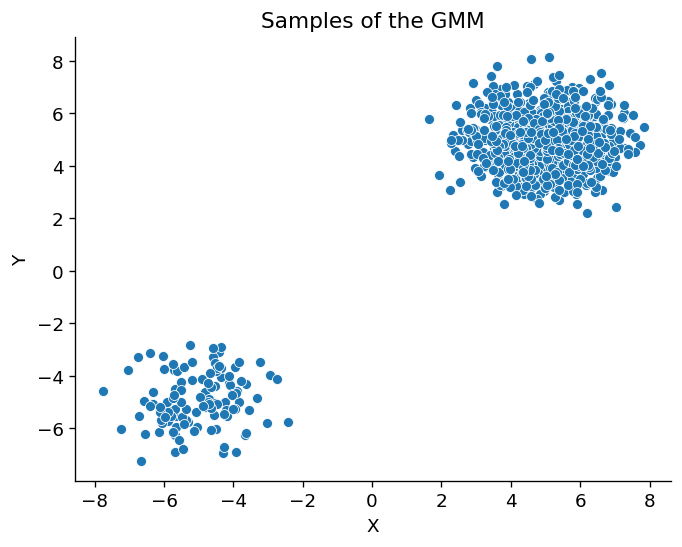

In [7]:
probs = [0.1, 0.90]
mus = np.asarray([
    [-1., -1.],
    [1., 1.]
]) * 5
sigmas = np.asarray([
    [1., 1.],
    [1., 1.]
])
gmm = GMM(probs, mus, sigmas, device=device)

samples = gmm.sample((1000,)).cpu()
sns.scatterplot(x=samples[:, 0], y=samples[:, 1])
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Samples of the GMM")
plt.show()

## Sampling with the exact score

$$x_{k+1}=x_k+\frac{\eta}{2}s(x_k)+\sqrt{\eta}\epsilon_k.$$

The score and random noise play different roles. We hold the step size and initial distribution fixed in this first experiment.

In [13]:
class LangevinDynamics:
    def __init__(self, score_fn: Callable, step_size: Tensor) -> None:
        self.score_fn = score_fn
        self.step_size = step_size
    
    def step(self, xt: Tensor, **kwargs: Dict) -> Tensor:
        noise = torch.randn_like(xt)
        return (xt + 0.5 * self.step_size * self.score_fn(xt, **kwargs) + self.step_size.sqrt() * noise)

    @torch.no_grad()
    def __call__(self, xt: Tensor, num_steps: int, **kwargs) -> Tensor:
        for _ in range(num_steps):
            xt = self.step(xt, **kwargs)
        return xt

###  Slow mixing of Langevin dynamics

For disjoint supports, the local score inside each component loses the mixture weight:
$$\nabla_x\log(\alpha p_1(x))=\nabla_x\log p_1(x).$$
Our Gaussian components are **not disjoint**. This is an approximation near a mode; the score does depend on the weights in the overlap region. Nevertheless, traversing the low-density gap can be very slow.

**Inspect:** do the final samples recover the 10% / 90% balance, or mostly preserve which basin they started in?

Source: [Song & Ermon, 2019, §3.2](https://arxiv.org/html/1907.05600v3#S3.SS2).

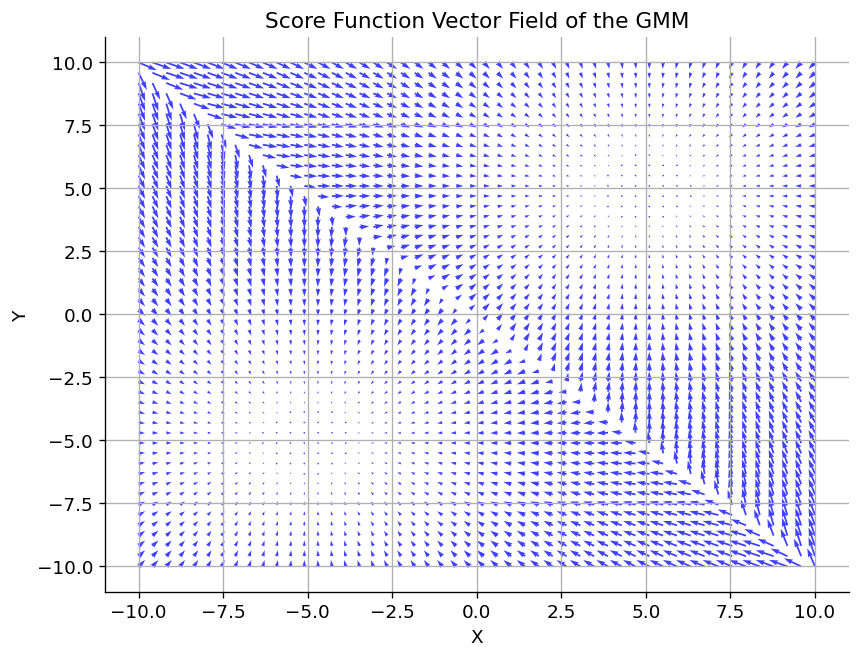

In [5]:
# Define the range for x and y values for grid points
x = np.linspace(-10, 10, 50)
y = np.linspace(-10, 10, 50)

# Create a meshgrid for x and y values
X, Y = np.meshgrid(x, y)
positions = np.vstack([X.ravel(), Y.ravel()]).T
positions_tensor = torch.tensor(positions, dtype=torch.float32)

# Calculate the score for each grid point
score = gmm.score(positions_tensor.to(device)).cpu()

# Convert score to numpy arrays for plotting
U = score[:, 0].detach().numpy().reshape(X.shape)  # x-component of the score
V = score[:, 1].detach().numpy().reshape(Y.shape)  # y-component of the score

# Plot: Vector field of the score function
plt.figure(figsize=(8, 6))
plt.quiver(X, Y, U, V, color="blue", alpha=0.75)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Score Function Vector Field of the GMM")
plt.grid(True)
plt.show()

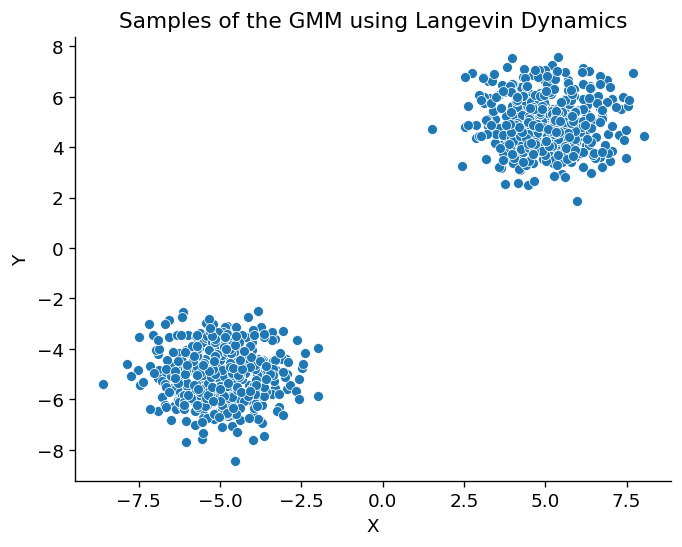

Left-mode fraction: 0.503; target: 0.100


In [14]:
ld = LangevinDynamics(step_size=torch.tensor(0.01), score_fn=gmm.score)

num_steps = 1000
x_start = (torch.rand((1000, 2)) - 0.5) * 16.
generations = ld(x_start.to(device), num_steps).cpu()
sns.scatterplot(x=generations[:, 0], y=generations[:, 1])
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Samples of the GMM using Langevin Dynamics")
plt.show()
# Nearest-center assignment is a diagnostic for these well-separated modes.
left_fraction = ((generations - torch.tensor([-5., -5.])).square().sum(1) < (generations - torch.tensor([5., 5.])).square().sum(1)).float().mean().item()
print(f"Left-mode fraction: {left_fraction:.3f}; target: 0.100")


## Inaccurate score estimates away from data

An accurate fit at training samples does not ensure an accurate vector field between the modes or far outside them. In this toy experiment we can train against the exact GMM score; this target is unavailable for real image data.

**Inspect:** compare the learned vector field with the exact field, especially in the low-density gap.

Let us define the Score Model:

In [7]:
class ScoreModel(nn.Module):
    def __init__(
        self, in_dim: int, hidden_dim: int
    ) -> None:
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, in_dim),
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.backbone(x)

class ScoreMatcher(BaseModel):
    def __init__(self, score_model, input_shape, score_fn, langevin_dynamics):
        super().__init__()
        self.score_model, self.input_shape = score_model, input_shape
        self.score_fn, self.langevin_dynamics = score_fn, langevin_dynamics

    def loss(self, x):
        return {"total_loss": 0.5 * (self.score_model(x) - self.score_fn(x)).square().sum(1).mean()}

    @torch.no_grad()
    def sample(self, num_samples=1000, num_steps=1000):
        x = (torch.rand(num_samples, *self.input_shape, device=self.device) - 0.5) * 16
        return self.langevin_dynamics(x, num_steps)


Epoch 1/150: train=2.55077, test=1.33456
Epoch 30/150: train=0.30313, test=0.29540
Epoch 60/150: train=0.12455, test=0.10881
Epoch 90/150: train=0.04929, test=0.03944
Epoch 120/150: train=0.01734, test=0.01480
Epoch 150/150: train=0.00493, test=0.00459


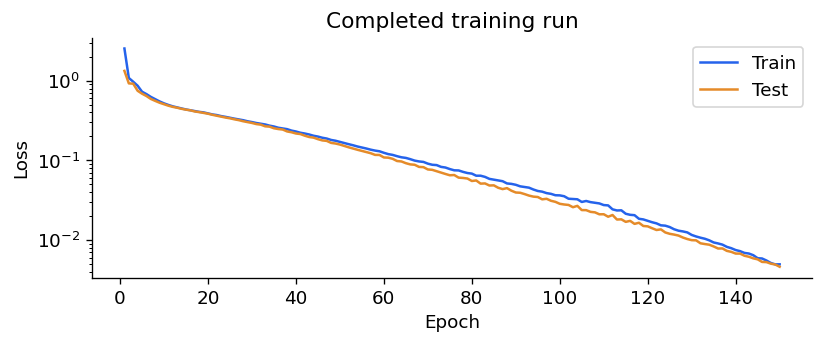

Epoch 60/150: train=0.12455, test=0.10881


Epoch 90/150: train=0.04929, test=0.03944


Epoch 120/150: train=0.01734, test=0.01480


Epoch 150/150: train=0.00493, test=0.00459


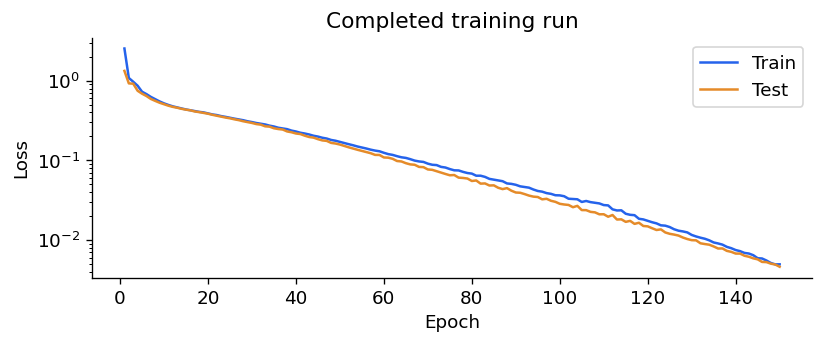

In [8]:
score_model = ScoreModel(2, 128).to(device)
estimate_ld = LangevinDynamics(step_size=torch.tensor(0.1), score_fn=score_model)

matcher = ScoreMatcher(
    score_model=score_model, 
    input_shape=(2,), 
    score_fn=gmm.score,
    langevin_dynamics=estimate_ld
)

train_loader = DataLoader(samples.to(torch.float32), batch_size=128, shuffle=True)
test_loader = DataLoader(gmm.sample((1000,)).cpu(), batch_size=128, shuffle=False)

optimizer = torch.optim.Adam(matcher.parameters(), lr=0.001)

baseline_history = train_model(
    matcher,
    train_loader,
    test_loader,
    epochs=150,
    optimizer=optimizer,
    device=device,
    visualize_samples=False,
    logscale_y=True,
)

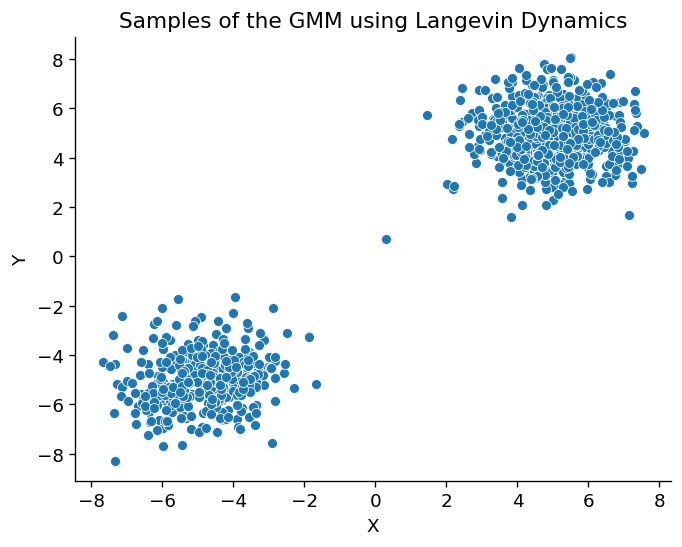

Left-mode fraction: 0.355; target: 0.100


In [9]:
num_steps = 1000
generations = matcher.sample(1000, num_steps=num_steps).cpu()

sns.scatterplot(x=generations[:, 0], y=generations[:, 1])
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Samples of the GMM using Langevin Dynamics")
plt.show()
# Nearest-center assignment is a diagnostic for these well-separated modes.
left_fraction = ((generations - torch.tensor([-5., -5.])).square().sum(1) < (generations - torch.tensor([5., 5.])).square().sum(1)).float().mean().item()
print(f"Left-mode fraction: {left_fraction:.3f}; target: 0.100")


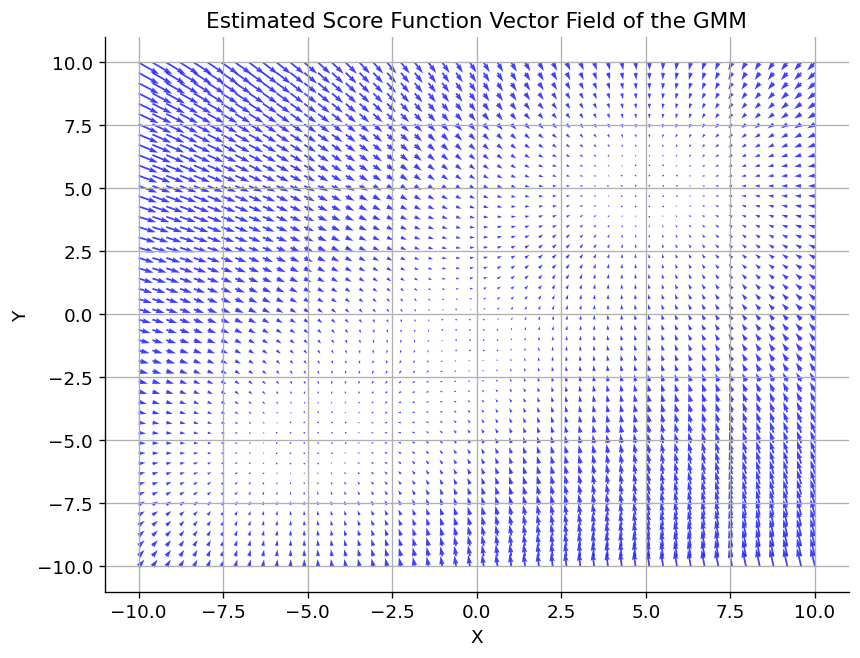

In [10]:
# Define the range for x and y values for grid points
x = np.linspace(-10, 10, 50)
y = np.linspace(-10, 10, 50)

# Create a meshgrid for x and y values
X, Y = np.meshgrid(x, y)
positions = np.vstack([X.ravel(), Y.ravel()]).T
positions_tensor = torch.tensor(positions, dtype=torch.float32)

# Calculate the score for each grid point
score = score_model(positions_tensor.to(device)).cpu()

# Convert score to numpy arrays for plotting
U = score[:, 0].detach().numpy().reshape(X.shape)  # x-component of the score
V = score[:, 1].detach().numpy().reshape(Y.shape)  # y-component of the score

# Plot: Vector field of the score function
plt.figure(figsize=(8, 6))
plt.quiver(X, Y, U, V, color="blue", alpha=0.75)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Estimated Score Function Vector Field of the GMM")
plt.grid(True)
plt.show()

## Solution of the problems using NCSN

**Main idea** is perturbing data with Gaussian noise.

1. Since the support of Gaussian noise distribution is the whole space, the perturbed data will not be confined to a low dimensional manifold, which obviates difficulties from the manifold hypothesis and makes score estimation well-defined.

2. Large Gaussian noise has the effect of filling low density regions in the original unperturbed data distribution; therefore score matching may get more training signal to improve score estimation.

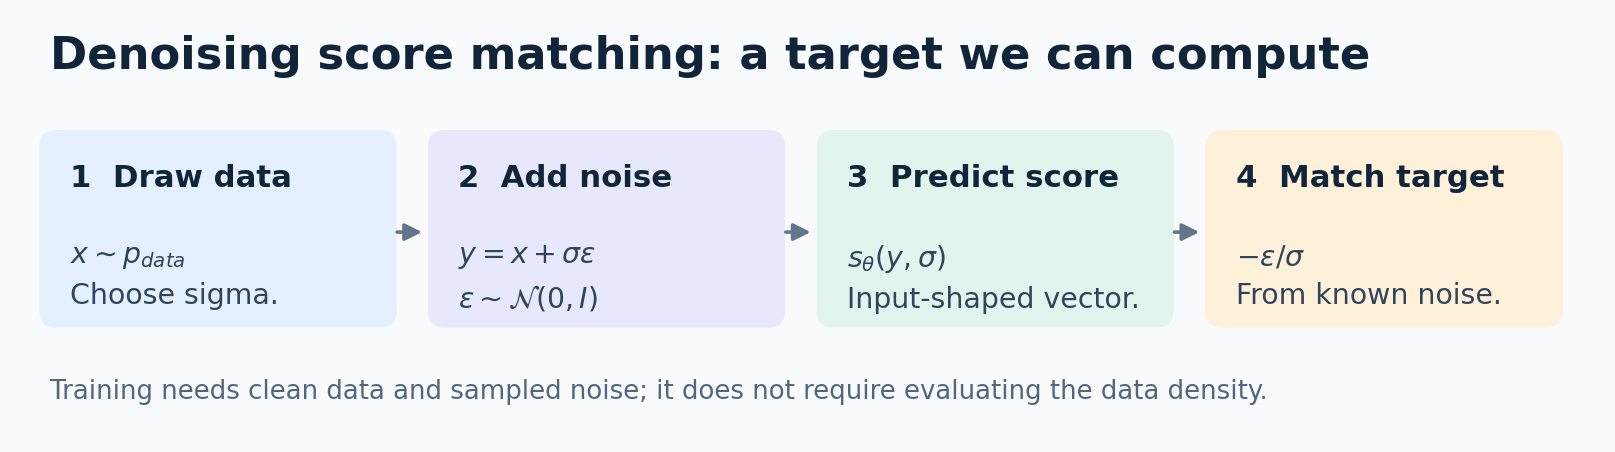

**Implementation convention:** pass the actual sigma value to the network in the loss, the sampler and every vector-field plot.

The network parameterizes $s_\theta(y,\sigma)=f_\theta(y,\sigma)/\sigma$, which matches the scale of the target. The weighted loss remains $\frac12\|\sigma s_\theta+\epsilon\|^2$.

In [11]:
class ConditionalScoreModel(nn.Module):
    def __init__(
        self, in_dim: int, sigma_emb_dim: int, hidden_dim: int
    ) -> None:
        super().__init__()
        self.sigma_emb = nn.Sequential(
            nn.Linear(1, sigma_emb_dim),
            nn.Softplus(),
            nn.Linear(sigma_emb_dim, sigma_emb_dim),
        )
        self.backbone = nn.Sequential(
            nn.Linear(in_dim + sigma_emb_dim, hidden_dim),
            nn.Softplus(),
            nn.Linear(hidden_dim, in_dim),
        )

    def forward(self, x: Tensor, sigma: Tensor) -> Tensor:
        sigma = sigma.float().reshape(-1, 1)
        sigma_emb = self.sigma_emb(sigma)
        x = torch.cat([x, sigma_emb], dim=1)
        return self.backbone(x) / sigma

class NoiseConditionedScoreNetwork(BaseModel):
    def __init__(self, score_model, input_shape, sigmas, langevin_dynamics):
        super().__init__()
        self.score_model, self.input_shape = score_model, input_shape
        self.register_buffer("sigmas", torch.tensor(sorted(sigmas, reverse=True), dtype=torch.float32))
        self.langevin_dynamics = langevin_dynamics
ynamics.step_size)

    def loss(self, x):
        levels = torch.randint(len(self.sigmas), (len(x),), device=x.device)
        sigma = self.sigmas[levels]  # Actual values, not indices, enter the network.
        noise = torch.randn_like(x)
        noisy_x = x + sigma[:, None] * noise
        score = self.score_model(noisy_x, sigma)
        residual = sigma[:, None] * score + noise
        return {"total_loss": 0.5 * residual.square().sum(1).mean()}

    @torch.no_grad()
    def sample(self, num_samples=1000, num_steps=500):
        x = self.sigmas[0] * torch.randn(num_samples, *self.input_shape, device=self.device)
        original_step = self.langevin_dynamics.step_size
        try:
            for sigma in self.sigmas:
                self.langevin_dynamics.step_size = self.eta_max * (sigma / self.sigmas[0]).square()
                levels = sigma.expand(num_samples)
                x = self.langevin_dynamics(x, num_steps, sigma=levels)
        finally:
            self.langevin_dynamics.step_size = original_step
        return x


Epoch 1/800: train=0.99556, test=0.89696
Epoch 160/800: train=0.59388, test=0.62682
Epoch 320/800: train=0.54280, test=0.63269
Epoch 480/800: train=0.56185, test=0.55809
Epoch 640/800: train=0.60110, test=0.53378
Epoch 800/800: train=0.58713, test=0.56574


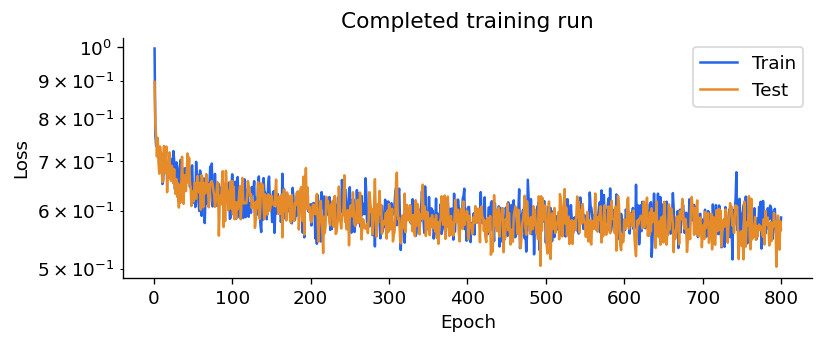

Epoch 320/800: train=0.54280, test=0.63269


Epoch 480/800: train=0.56185, test=0.55809


Epoch 640/800: train=0.60110, test=0.53378


Epoch 800/800: train=0.58713, test=0.56574


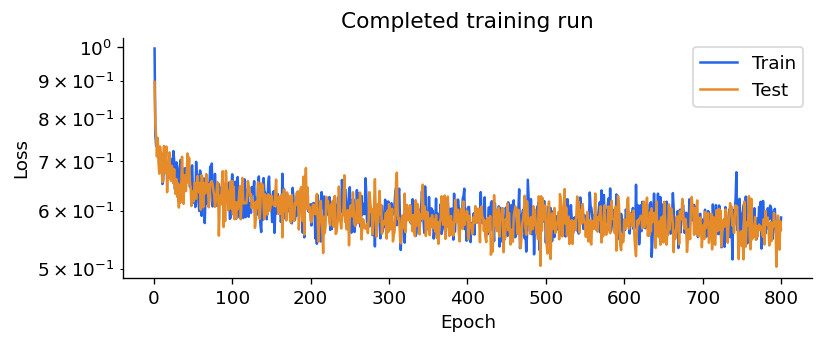

In [12]:
cond_score_model = ConditionalScoreModel(2, 16, 128).to(device)
estimate_ld = LangevinDynamics(step_size=torch.tensor(1.0), score_fn=cond_score_model)

sigma_1 = 8.
sigma_L = 0.1
L = 10
sigmas = [
    sigma_1 * (sigma_L/sigma_1)**((i)/(L-1)) for i in range(L)
]
matcher = NoiseConditionedScoreNetwork(
    score_model=cond_score_model, 
    input_shape=(2,), 
    sigmas=sigmas,
    langevin_dynamics=estimate_ld
).to(device)

train_loader = DataLoader(samples.to(torch.float32), batch_size=128, shuffle=True)
test_loader = DataLoader(gmm.sample((1000,)).cpu(), batch_size=128, shuffle=False)

optimizer = torch.optim.Adam(matcher.parameters(), lr=0.001)

ncsn_history = train_model(
    matcher,
    train_loader,
    test_loader,
    epochs=800,
    optimizer=optimizer,
    device=device,
    visualize_samples=False,
    logscale_y=True,
)

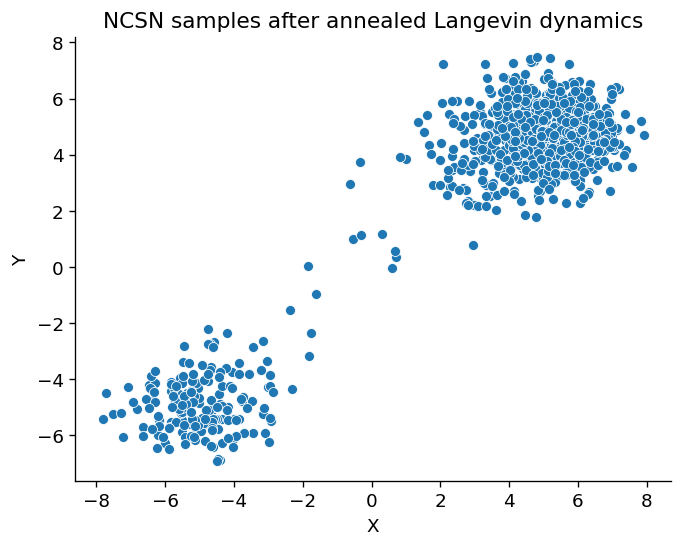

Left-mode fraction: 0.180; target: 0.100


In [13]:
num_steps = 500  # Steps per noise level.
generations = matcher.sample(1000, num_steps=num_steps).cpu()

sns.scatterplot(x=generations[:, 0], y=generations[:, 1])
plt.xlabel("X")
plt.ylabel("Y")
plt.title("NCSN samples after annealed Langevin dynamics")
plt.show()
# Nearest-center assignment is a diagnostic for these well-separated modes.
left_fraction = ((generations - torch.tensor([-5., -5.])).square().sum(1) < (generations - torch.tensor([5., 5.])).square().sum(1)).float().mean().item()
print(f"Left-mode fraction: {left_fraction:.3f}; target: 0.100")


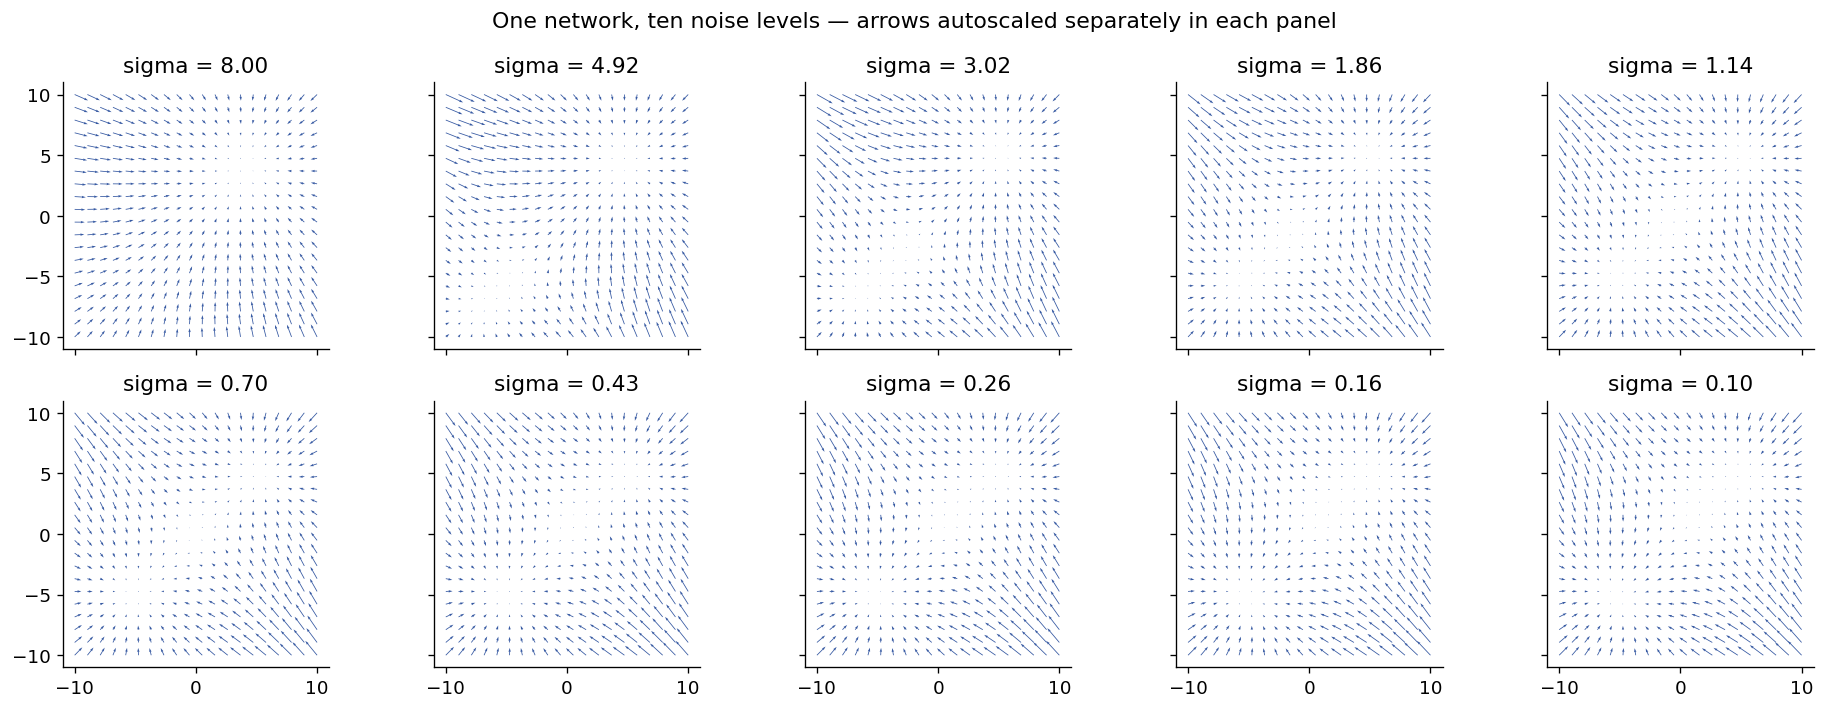

In [14]:
x = np.linspace(-10, 10, 20)
X, Y = np.meshgrid(x, x)
points = torch.tensor(np.c_[X.ravel(), Y.ravel()], dtype=torch.float32, device=device)
fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharex=True, sharey=True)
with torch.no_grad():
    for ax, sigma in zip(axes.flat, matcher.sigmas):
        field = cond_score_model(points, sigma.expand(len(points))).cpu().numpy()
        ax.quiver(X, Y, field[:, 0].reshape(X.shape), field[:, 1].reshape(Y.shape), color="#3659a2")
        ax.set_title(f"sigma = {sigma.item():.2f}")
        ax.set_aspect("equal")
fig.suptitle("One network, ten noise levels — arrows autoscaled separately in each panel")
plt.tight_layout(); plt.show()


## Animated sampling: vector field + particles

Watch the **same 1,000 particles** across all ten noise levels, from $\sigma=8$ to $0.1$. The arrows update when the noise level changes; the particles continue from their current positions. The model and step-size schedule are the same as above (500 updates per level).

- **Left:** the full cloud. **Right:** a close-up of the two modes. Both cameras stay fixed.
- **Arrows show direction only:** they are normalized to a common length. The actual sampler uses the full, unnormalized score and fresh random noise at every update.
- **Left share** counts particles nearest the left centre, using all particles, including those outside the displayed range. At high noise this is a geometric diagnostic, not a mixture-component assignment.
- This is a **new sampling run**, with animation seed `20261028`; its final percentages need not exactly match the static plot above.

**Discuss:** when does the left/right balance change most, and when do the two clouds mainly become sharper?

The looping GIF is embedded below and plays without execution in Jupyter. A static fallback is included for viewers that do not render HTML. To regenerate it, run the NCSN training cell first, then the cell below. The cell preserves the random state used by the other experiments.


Animation: 10 levels × 500 updates; seed 20261028; final left share 16.0%.


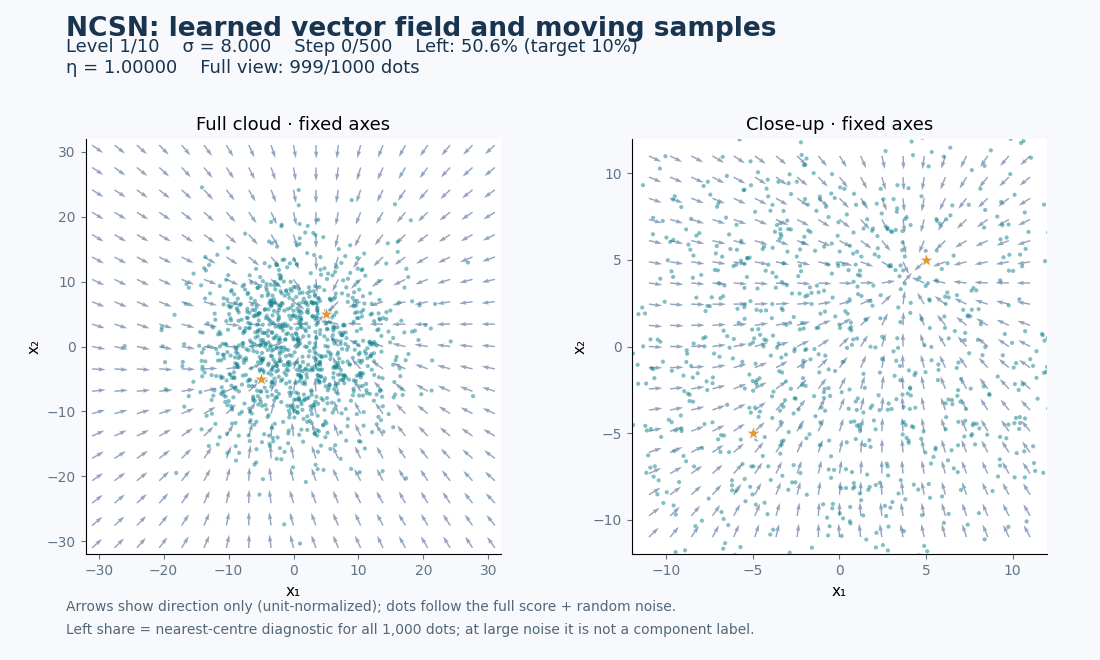

In [ ]:
# Run after the NCSN training cell. The saved output plays without running this cell.
import base64
from io import BytesIO
from PIL import Image as PILImage
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython.display import display


def make_ncsn_animation(ncsn, seed=20261028, num_samples=1000,
                        steps_per_level=500, frame_every=50):
    """Animate a new seeded trajectory using the trained score network."""
    if not isinstance(ncsn, NoiseConditionedScoreNetwork):
        raise ValueError("Run the noise-conditioned model training cell first.")
    model = ncsn.score_model
    was_training = model.training
    generator = torch.Generator(device=ncsn.device).manual_seed(seed)
    sigmas = ncsn.sigmas
    x = sigmas[0] * torch.randn(num_samples, 2, device=ncsn.device,
                                generator=generator)
    centers = torch.tensor([[-5., -5.], [5., 5.]], device=ncsn.device)
    fig = Figure(figsize=(11, 6.6), dpi=100, facecolor="#f7f9fc")
    canvas = FigureCanvasAgg(fig)
    axes = fig.subplots(1, 2)
    fig.subplots_adjust(left=.06, right=.97, bottom=.16, top=.79, wspace=.20)
    fig.suptitle("NCSN: learned vector field and moving samples",
                 x=.06, ha="left", y=.975, fontsize=19, weight="bold", color="#18344e")
    status = fig.text(.06, .89, "", fontsize=13, color="#18344e")
    fig.text(.06, .075, "Arrows show direction only (unit-normalized); dots follow the full score + random noise.",
             fontsize=10, color="#536779")
    fig.text(.06, .04, "Left share = nearest-centre diagnostic for all 1,000 dots; at large noise it is not a component label.",
             fontsize=10, color="#536779")
    grids, arrows, dots = [], [], []
    for ax, bound, title in zip(axes, [32, 12], ["Full cloud · fixed axes", "Close-up · fixed axes"]):
        grid = np.linspace(-bound + 1, bound - 1, 19)
        xx, yy = np.meshgrid(grid, grid)
        grids.append(torch.tensor(np.c_[xx.ravel(), yy.ravel()],
                                  dtype=torch.float32, device=ncsn.device))
        arrows.append(ax.quiver(xx, yy, np.zeros_like(xx), np.zeros_like(yy),
                               angles="xy", scale_units="xy", scale=1/(bound*.065),
                               color="#8097b5", alpha=.85, width=.0035, zorder=1))
        dots.append(ax.scatter([], [], s=9, color="#087f8c", alpha=.50,
                               edgecolors="none", zorder=2))
        ax.scatter([-5, 5], [-5, 5], marker="*", s=125, color="#e59737",
                   edgecolors="white", linewidths=.7, zorder=3)
        ax.set(xlim=(-bound, bound), ylim=(-bound, bound), aspect="equal",
               xlabel="x₁", ylabel="x₂", title=title)
        ax.set_facecolor("white")
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(colors="#617487", labelsize=10)
    frames, durations, diagnostics = [], [], []
    first_png = None

    def capture(level, step, sigma, eta):
        nonlocal first_png
        xy = x.detach().cpu().numpy()
        assert np.isfinite(xy).all(), "Non-finite sample encountered"
        share = (x[:, 0] + x[:, 1] < 0).float().mean().item()
        visible = ((np.abs(xy) <= 32).all(axis=1)).sum()
        for dot in dots:
            dot.set_offsets(xy)
        status.set_text(f"Level {level+1}/{len(sigmas)}    σ = {float(sigma):.3f}    "
                        f"Step {step}/{steps_per_level}    Left: {share:.1%} (target 10%)\n"
                        f"η = {float(eta):.5f}    Full view: {visible}/{num_samples} dots")
        canvas.draw()
        rgba = np.asarray(canvas.buffer_rgba()).copy()
        frame = PILImage.fromarray(rgba).convert("RGB")
        if first_png is None:
            buffer = BytesIO(); frame.save(buffer, format="PNG"); first_png = buffer.getvalue()
        frames.append(frame.quantize(palette=frames[0], dither=PILImage.Dither.NONE)
                      if frames else frame.quantize(colors=128, method=PILImage.Quantize.MEDIANCUT))
        durations.append(650 if step == 0 else 300)
        diagnostics.append((level, step, float(sigma), share))

    model.eval()
    try:
        with torch.no_grad():
            for level, sigma in enumerate(sigmas):
                eta = ncsn.eta_max * (sigma / sigmas[0]).square()
                for grid, quiver in zip(grids, arrows):
                    field = model(grid, sigma.expand(len(grid)))
                    assert torch.isfinite(field).all(), "Non-finite vector field"
                    field = field / field.norm(dim=1, keepdim=True).clamp_min(1e-8)
                    uv = field.cpu().numpy()
                    quiver.set_UVC(uv[:, 0], uv[:, 1])
                capture(level, 0, sigma, eta)
                for step in range(1, steps_per_level + 1):
                    noise = torch.randn(x.shape, device=x.device, dtype=x.dtype,
                                        generator=generator)
                    x = x + .5 * eta * model(x, sigma.expand(num_samples)) + eta.sqrt() * noise
                    if step % frame_every == 0 or step == steps_per_level:
                        capture(level, step, sigma, eta)
                print(f"Animation level {level+1}/{len(sigmas)}: σ={float(sigma):.3f}, "
                      f"left share={diagnostics[-1][-1]:.1%}", flush=True)
    finally:
        model.train(was_training)
    durations[-1] = 3000  # Pause at the result before looping.
    buffer = BytesIO()
    frames[0].save(buffer, format="GIF", save_all=True, append_images=frames[1:],
                   duration=durations, loop=0, optimize=True, disposal=1)
    return buffer.getvalue(), first_png, diagnostics


ncsn_gif, ncsn_poster, ncsn_animation_log = make_ncsn_animation(matcher)
# Both representations are embedded: GIF for Jupyter, static fallback for other viewers.
display({
    "text/html": '<img alt="NCSN sampling with a learned vector field at decreasing noise levels" '
                 'style="max-width:100%;height:auto" src="data:image/gif;base64,'
                 + base64.b64encode(ncsn_gif).decode("ascii") + '">',
    "image/png": base64.b64encode(ncsn_poster).decode("ascii"),
    "text/plain": "NCSN animation · 10 noise levels · 500 steps per level · 1,000 samples"
}, raw=True)


## How to choose hyperparameters?
Details in the [paper](https://arxiv.org/abs/2006.09011).

The following high-dimensional heuristics are reference material; our 2D demonstration uses a small fixed budget. They are not universal guarantees.

**Technique 0**:
choose $\sigma_L$ in a way that $q_{\sigma_L}(x) \approx \pi(x)$.

**Technique 1** (Initial noise scale):
choose $\sigma_1$ to be as large as the maximum Euclidean distance between all pairs of training data points.

This is a heuristic motivated by a finite-dataset analysis; it can be sensitive to outliers.

**Technique 2** (Other noise scales):
choose $\{\sigma_i\}$ as a geometric progression with a common ratio $\gamma$,
such that $\Phi(\sqrt{2D}(\gamma - 1) + 3 \gamma) - \Phi(\sqrt{2D}(\gamma - 1) - 3 \gamma) \approx 0.5$, where $D$ is a data dimensionality (should be large).

Here $\gamma=\sigma_{i-1}/\sigma_i>1$, and $\Phi$ is the standard normal CDF.

**Technique 3** (selecting $T$ and $\epsilon$):
choose $T$ as large as allowed by a computing budget and then select an
$\epsilon$ that makes equation below maximally close to 1.

$$
    f(\epsilon)
    =
    \left(
        1 - \frac{\epsilon}{\sigma_L^2}
    \right)^{2T}
    \left(
        \gamma^2
        -
        \frac{
            2 \epsilon
        }{
            \sigma_L^2
            -
            \sigma_L^2
            (1 - \frac{\epsilon}{\sigma_L^2})^2
        }
    \right)
    +
    \frac{
        2 \epsilon
    }{
        \sigma_L^2
        -
        \sigma_L^2
        (1 - \frac{\epsilon}{\sigma_L^2})^2
    }
$$

**Convention:** the cited analysis uses $x\leftarrow x+\alpha s+\sqrt{2\alpha}\epsilon$. Our code uses $\eta/2$ and $\sqrt{\eta}$, so $\eta=2\alpha$. Do not transfer the step-size parameter without this factor of two.

With the paper’s $\alpha_i=\varepsilon(\sigma_i/\sigma_L)^2$, our equivalent setting is $\eta_{max}=2\varepsilon(\sigma_1/\sigma_L)^2$. Here $T$ in the reference formula is the number of steps at each noise level (called `num_steps` in code).

## Takeaways

- Exact scores alone do not guarantee fast mixing.
- A local score fit can fail far from training data.
- Gaussian perturbations and noise conditioning expand the training coverage.
- The noise convention and step-size schedule must match across training and sampling.
- Check mode proportions and vector fields, not only the loss.

**Next:** [predict the clean MNIST image directly](denoising_model.ipynb).

**Read the saved experiment honestly:** the printed left-mode fraction should be compared with 0.10. Our small NCSN improves the balance but retains sampling and score-estimation error; a low training loss is not a guarantee of correct mixture weights.